# SolarROI — walkthrough

A guided tour of the pipeline: read the screenshots, clean the bills, build the
counterfactual, project the cash flows, and put error bars on the answer.

Every step here is the same code the Streamlit app runs — nothing in the app is
reimplemented for the notebook.

In [1]:
import sys, warnings, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

## 1. Reading the ShinePhone charts

The app exports nothing, so the numbers are measured off the bars in pixels.
OCR at this font size is unreliable — both axes are calibrated by consensus
instead of by trusting individual labels.

In [2]:
from src.vision import extract_chart

shots = sorted(pathlib.Path("../data/samples").glob("shinephone_*"))
extractions = [extract_chart(str(p)) for p in shots]

for e, p in zip(extractions, shots):
    print(f"{p.name:34s} {e.kind:6s} {e.year or '':6} "
          f"{len(e.values):2d} bars  confidence {e.confidence:.0%}")
    print(f"   y-axis: {e.debug['y_detail'][:88]}")

shinephone_month_2023.png          month    2023  7 bars  confidence 89%
   y-axis: step=40 kWh over 50.2px; labels read: ['240.0', '200.0', '160.0', '120.0', '30.0', '40.0
shinephone_month_2024.jpg          month    2024 12 bars  confidence 90%
   y-axis: step=50 kWh over 56.5px; labels read: ['290.0', '200.0', '190.0', '100.0', '90.0', '0.0'
shinephone_month_2025.jpg          month    2025 12 bars  confidence 97%
   y-axis: step=50 kWh over 59.0px; labels read: ['250.0', '200.0', '150.0', '100.0', '90.0', '0.0'
shinephone_month_2026.jpg          month    2026  8 bars  confidence 83%
   y-axis: step=50 kWh over 57.5px; labels read: ['290.0', '200.0', '130.0', '100.0', '50.0', '0.0'
shinephone_year.jpg                year           4 bars  confidence 82%
   y-axis: step=500 kWh over 58.5px; labels read: ['2900.0', '2000.0', '1900.0', '1000.0', '900.0',


### Validating the extraction

The bill CSV independently records metered generation for 30 of these months,
so the pixel measurement can be scored against ground truth rather than
against itself.

months validated : 30
MAPE             : 1.01%
worst month      : 2.85%


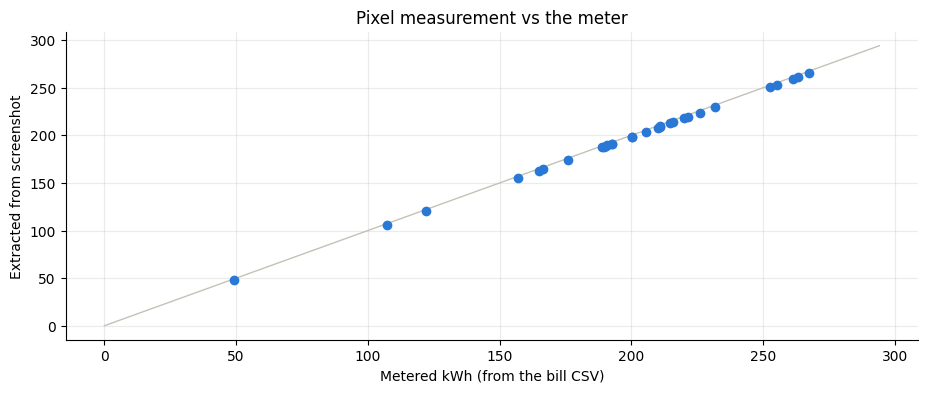

In [3]:
truth = pd.read_csv("../data/billdata.csv").groupby(["year", "month"])["solar_kwh"].max()

rows = []
for e in extractions:
    if e.kind != "month":
        continue
    for period, value in zip(e.periods, e.values):
        actual = truth.get((e.year, period))
        if actual and actual > 0:
            rows.append({"year": e.year, "month": period, "extracted": value,
                         "metered": actual, "error_%": (value - actual) / actual * 100})

check = pd.DataFrame(rows)
print(f"months validated : {len(check)}")
print(f"MAPE             : {check['error_%'].abs().mean():.2f}%")
print(f"worst month      : {check['error_%'].abs().max():.2f}%")

fig, ax = plt.subplots()
ax.scatter(check["metered"], check["extracted"], color=BLUE, s=36, zorder=3)
lims = [0, check["metered"].max() * 1.1]
ax.plot(lims, lims, color="#c3c2b7", lw=1, zorder=2)
ax.set(xlabel="Metered kWh (from the bill CSV)", ylabel="Extracted from screenshot",
       title="Pixel measurement vs the meter")
plt.show()

## 2. Cleaning the bills

Utility exports are messy. Every repair is recorded as a flag, never applied
silently — the flags are what let the models exclude the rows that would
distort them.

In [4]:
from src.ingest import load_bills, clean_bills, modelling_frame, merge_generation
from src.pipeline import extractions_to_frame

bills, quality = clean_bills(load_bills("../data/billdata.csv"))
bills, ext_stats = merge_generation(bills, extractions_to_frame(extractions))

for line in quality.to_lines():
    print(line)
print()
print("screenshot merge:", ext_stats)

Rows read: 105 -> 108 after cleaning
Coverage: 2016-12 to 2025-11
Solar commissioned: 2023-06
Duplicate months merged: 1 ['2023-07']
Repeated (bi-monthly) readings flagged: 9
Credit-adjustment bills flagged: 6 ['2019-11', '2019-12', '2020-01', '2020-02', '2020-06', '2025-02']
Missing months imputed: 4 ['2020-05', '2020-08', '2021-04', '2021-06']
Billing anomalies (arrears / true-up) flagged: 1 ['2023-07']

screenshot merge: {'overlap_n': 30, 'overlap_mape': 1.011608483203639, 'months_added': 9, 'months_updated': 9}


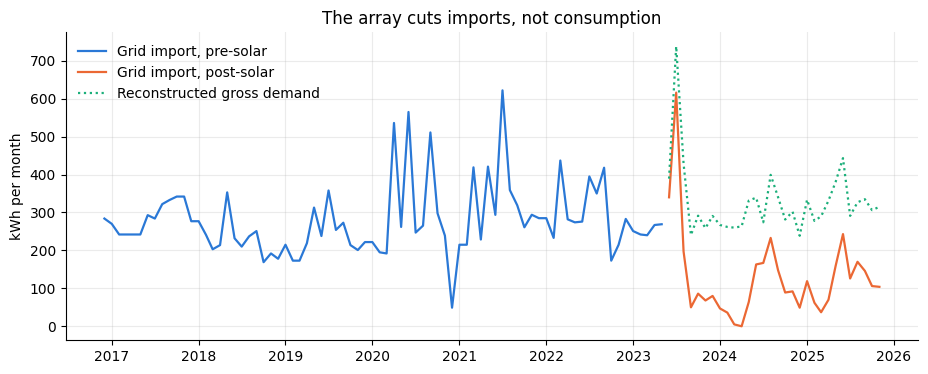

mean grid import  before:    279 kWh
                   after:    129 kWh
mean self-sufficiency   :  49.7%


In [5]:
fig, ax = plt.subplots()
pre = bills[bills["solar_kwh"] == 0]
post = bills[bills["solar_kwh"] > 0]
ax.plot(pre["date"], pre["grid_kwh"], color=BLUE, lw=1.6, label="Grid import, pre-solar")
ax.plot(post["date"], post["grid_kwh"], color=ORANGE, lw=1.6, label="Grid import, post-solar")
ax.plot(post["date"], post["total_consumption_kwh"], color=AQUA, lw=1.6, ls=":",
        label="Reconstructed gross demand")
ax.legend(frameon=False)
ax.set(ylabel="kWh per month", title="The array cuts imports, not consumption")
plt.show()

print(f"mean grid import  before: {pre['grid_kwh'].mean():6.0f} kWh")
print(f"                   after: {post['grid_kwh'].mean():6.0f} kWh")
print(f"mean self-sufficiency   : {post['self_sufficiency'].mean():6.1%}")

## 3. The counterfactual

Everything rests on the bill that never arrived. Two independent estimators:

**A — tariff surrogate.** Learn `bill = f(units, calendar time)` from the bills,
then ask it what gross demand would have cost.

**B — synthetic counterfactual.** Fit only pre-solar months on calendar
features and extrapolate the trajectory forward. Never sees generation.

In [6]:
from src.models import TariffModel, SyntheticCounterfactual

model_df = modelling_frame(bills)
origin, commissioning = bills["period"].iloc[0], post["period"].iloc[0]

tariff = TariffModel(origin=origin).fit(model_df)
synthetic = SyntheticCounterfactual(origin=origin).fit(model_df[model_df["period"] < commissioning])

print("tariff model     :", tariff.fitted.name)
print(tariff.fitted.leaderboard[["MAE", "RMSE", "MAPE_%", "R2"]].round(2), "\n")
print("synthetic control:", synthetic.fitted.name)
print(synthetic.fitted.leaderboard[["MAE", "MAPE_%", "R2", "selectable"]].round(2))

tariff model     : Ridge
                          MAE    RMSE  MAPE_%    R2
model                                              
Ridge                  148.11  202.03   30.15  0.41
Huber (robust linear)  153.97  229.95   29.42  0.20
ExtraTrees             159.34  194.77   32.27  0.47
RandomForest           163.40  204.53   33.97  0.42
GradientBoosting       208.50  245.62   45.96  0.16
Baseline (mean)        289.87  356.18   70.63 -0.81 

synthetic control: Ridge
                          MAE  MAPE_%    R2  selectable
model                                                  
ExtraTrees             219.67   28.95 -0.05       False
GradientBoosting       224.27   29.74 -0.08       False
Ridge                  232.39   28.54 -0.31        True
RandomForest           232.42   30.42 -0.16       False
Baseline (mean)        242.78   31.83 -0.49        True
Huber (robust linear)  259.26   30.77 -0.64        True


Note what the second leaderboard shows: tree ensembles score *better* on
cross-validated MAE and are still excluded (`selectable = False`). A tree
predicts a constant outside its training range, so a model whose whole job is
extrapolating a trend into unseen years cannot be one. The leaderboard reports
the trade-off rather than hiding it.

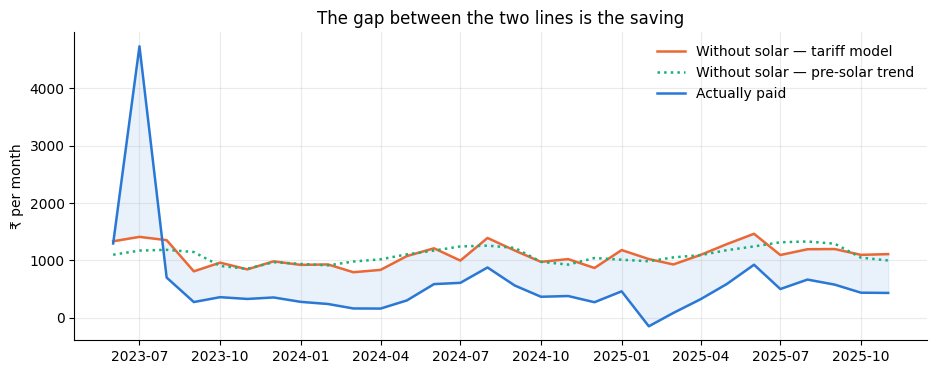

average monthly saving : ₹634
realised to date       : ₹19,020 (as billed ₹14,940)
value of a unit        : ₹3.19/kWh
the two methods agree  : 77%


In [7]:
from src.roi import historical_savings, realised_summary

era = bills[(bills["period"] >= commissioning) & bills["bill_amount"].notna()].copy()
history = historical_savings(era, tariff, synthetic)
realised = realised_summary(history, capex=170_000)

fig, ax = plt.subplots()
ax.plot(history["date"], history["counterfactual_bill_tariff"], color=ORANGE, lw=1.8,
        label="Without solar — tariff model")
ax.plot(history["date"], history["counterfactual_bill_synthetic"], color=AQUA, lw=1.8, ls=":",
        label="Without solar — pre-solar trend")
ax.plot(history["date"], history["bill_amount"], color=BLUE, lw=1.8, label="Actually paid")
ax.fill_between(history["date"], history["bill_amount"],
                history["counterfactual_bill_tariff"], color=BLUE, alpha=0.10)
ax.legend(frameon=False)
ax.set(ylabel="₹ per month", title="The gap between the two lines is the saving")
plt.show()

print(f"average monthly saving : ₹{realised['avg_monthly_savings']:,.0f}")
print(f"realised to date       : ₹{realised['total_savings']:,.0f} "
      f"(as billed ₹{realised['total_savings_as_billed']:,.0f})")
print(f"value of a unit        : ₹{realised['realised_value_per_kwh']:.2f}/kWh")
print(f"the two methods agree  : {realised['counterfactual_agreement_pct']:.0f}%")

The as-billed total is lower because one month carries a ₹2,469 arrears bill
for 57 units — money belonging to earlier months. The headline figure is the
mean saving over clean months scaled to the observed span, so a single true-up
bill cannot swallow a fifth of the measured return.

**Marginal vs average rate.** Because the tariff is block-rate, generation
displaces the *top* slab. Using the average rate on the bill is the most common
way household solar ROI gets understated:

In [8]:
avg_rate = history["bill_amount"].sum() / history["grid_kwh"].sum()
print(f"average rate on the bill    : ₹{avg_rate:.2f}/kWh")
print(f"modelled marginal rate      : ₹{history['marginal_rate'].median():.2f}/kWh")
print(f"realised value per unit     : ₹{realised['realised_value_per_kwh']:.2f}/kWh")

average rate on the bill    : ₹4.55/kWh
modelled marginal rate      : ₹3.10/kWh
realised value per unit     : ₹3.19/kWh


## 4. Generation, degradation and panel health

In [9]:
from src.models import GenerationModel, detect_anomalies

gen_model = GenerationModel(commissioning=commissioning, origin=origin)
gen_fit = gen_model.fit(bills[bills["solar_kwh"] > 0].copy())
flags = detect_anomalies(gen_fit)

print(f"selected model     : {gen_fit.model.name} "
      f"(CV MAPE {gen_fit.model.cv_metrics['MAPE_%']:.1f}%)")
print(f"typical year       : {gen_fit.annual_yield_kwh:,.0f} kWh")
print(f"degradation in data: {gen_fit.fitted_degradation:+.3%}/yr  "
      "← noise, not panels improving: 2.5 years is too short to measure it")

print(flags[flags["severity"] != "ok"][["period", "solar_kwh", "predicted_kwh",
                                        "shortfall_pct", "severity"]].round(1).to_string(index=False))

selected model     : ExtraTrees (CV MAPE 9.9%)
typical year       : 2,477 kWh
degradation in data: -7.531%/yr  ← noise, not panels improving: 2.5 years is too short to measure it
 period  solar_kwh  predicted_kwh  shortfall_pct     severity
2023-06       49.2           97.6           49.6      ramp-up
2023-07      122.2           97.5          -25.3 above normal
2023-08      231.6          192.9          -20.0 above normal
2024-07      107.1          140.5           23.8         high
2025-05      221.6          245.2            9.6        watch


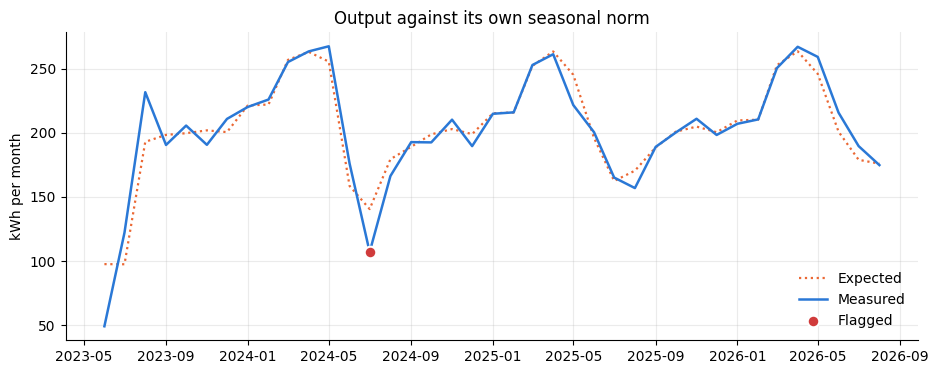

In [10]:
dates = flags["period"].dt.to_timestamp()
fig, ax = plt.subplots()
ax.plot(dates, flags["predicted_kwh"], color=ORANGE, lw=1.6, ls=":", label="Expected")
ax.plot(dates, flags["solar_kwh"], color=BLUE, lw=1.8, label="Measured")
bad = flags[flags["severity"] == "high"]
ax.scatter(bad["period"].dt.to_timestamp(), bad["solar_kwh"], color="#d03b3b", s=70,
           zorder=4, label="Flagged", edgecolor="white", linewidth=1.5)
ax.legend(frameon=False)
ax.set(ylabel="kWh per month", title="Output against its own seasonal norm")
plt.show()

## 5. Payback, with error bars

Measure the past, model only the future: realised months contribute what they
actually saved, and the projection starts the month after the last bill.

In [11]:
from src.pipeline import run_analysis
from src.config import FinancialAssumptions, MonteCarloAssumptions

result = run_analysis("../data/billdata.csv", extractions_to_frame(extractions),
                      FinancialAssumptions(capex=170_000),
                      MonteCarloAssumptions(n_simulations=10_000))

for key, value in result.headline().items():
    print(f"{key:<34} {value if isinstance(value, str) else f'{value:,.2f}'}")

Payback (blended, years)           18.60
Payback P50 (simulated)            18.90
Payback P10 - P90                  16.1 - 22.6
Capex recovered so far (%)         11.19
Realised savings to date (INR)     19,019.80
NPV @ 7% (INR)                     -57,139.98
IRR (%)                            3.60
LCOE (INR/kWh)                     6.77
25-year ROI (%)                    67.60
CO2 avoided to date (kg)           4,228.55


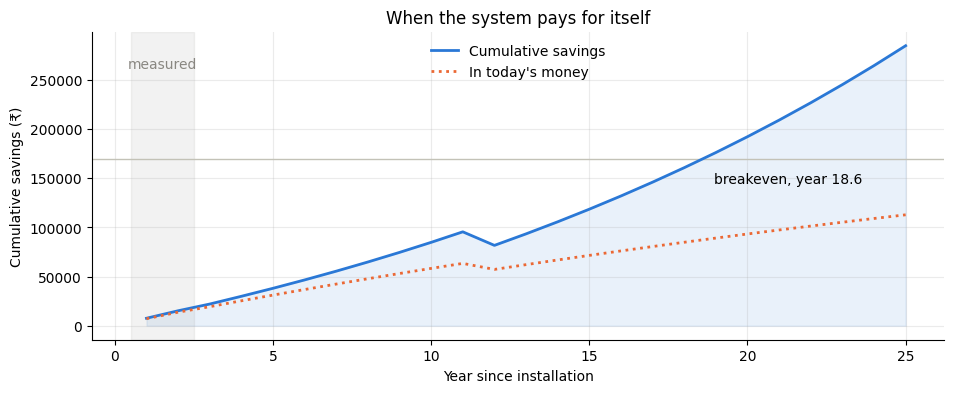

In [12]:
sched = result.payback.schedule
fig, ax = plt.subplots()
ax.axhline(result.assumptions.capex, color="#c3c2b7", lw=1)
ax.plot(sched["year"], sched["cumulative"], color=BLUE, lw=2, label="Cumulative savings")
ax.plot(sched["year"], sched["cumulative_discounted"], color=ORANGE, lw=2, ls=":",
        label="In today's money")
ax.fill_between(sched["year"], 0, sched["cumulative"], color=BLUE, alpha=0.10)
n_real = (sched["source"] == "realised").sum()
ax.axvspan(0.5, n_real + 0.5, color="#898781", alpha=0.10)
ax.annotate("measured", (n_real / 2 + 0.5, sched["cumulative"].max() * 0.92),
            ha="center", color="#898781")
ax.annotate(f"breakeven, year {result.payback.simple_payback_years:.1f}",
            (result.payback.simple_payback_years, result.assumptions.capex),
            xytext=(8, -18), textcoords="offset points")
ax.legend(frameon=False)
ax.set(xlabel="Year since installation", ylabel="Cumulative savings (₹)",
       title="When the system pays for itself")
plt.show()

### The uncertainty is the point

10,000 paths, each with its own tariff escalation, degradation, weather and
chance of a fault. The realised era is held fixed — resimulating months that
already happened would manufacture false uncertainty.

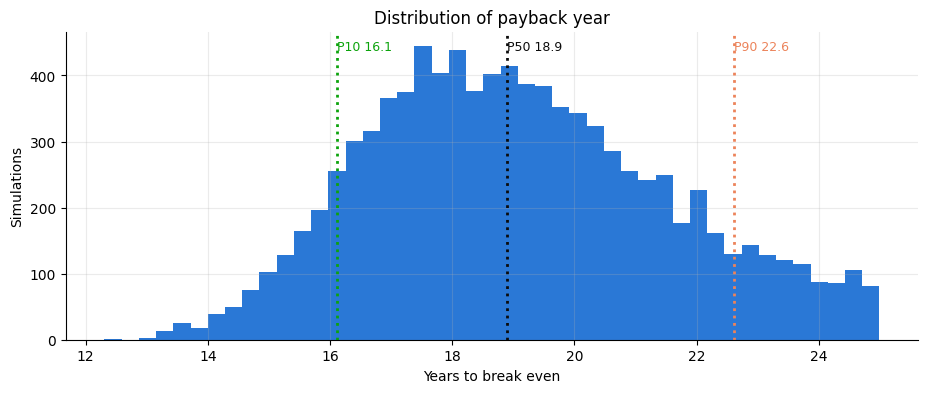

breaks even within 25 years: 93% of paths
clears a 7% discount rate      : 4% of paths


In [13]:
mc = result.monte_carlo
valid = mc.paybacks[~np.isnan(mc.paybacks)]

fig, ax = plt.subplots()
ax.hist(valid, bins=45, color=BLUE)
for label, value, colour in [("P10", mc.p10, "#0ca30c"), ("P50", mc.p50, "#0b0b0b"),
                             ("P90", mc.p90, "#ec835a")]:
    ax.axvline(value, color=colour, ls=":", lw=2)
    ax.annotate(f"{label} {value:.1f}", (value, ax.get_ylim()[1] * 0.94),
                color=colour, ha="left", fontsize=9)
ax.set(xlabel="Years to break even", ylabel="Simulations",
       title="Distribution of payback year")
plt.show()

print(f"breaks even within {result.assumptions.system_life_years} years: "
      f"{mc.prob_within_life:.0%} of paths")
print(f"clears a {result.assumptions.discount_rate:.0%} discount rate      : "
      f"{mc.prob_positive_npv:.0%} of paths")

Those two lines are the honest summary of this investment: it will very likely
return its cost in cash, and it will very likely not beat a fixed deposit.
Goa's tariff is cheap enough that each generated unit is only worth about ₹3.2,
so the payback case rests on tariffs rising.

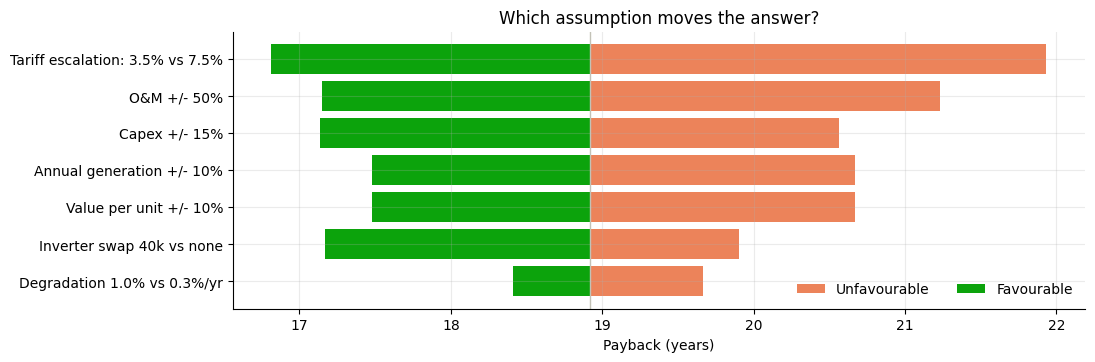

In [14]:
sens = result.sensitivity
fig, ax = plt.subplots(figsize=(11, 3.6))
y = np.arange(len(sens))
base = sens["base"].iloc[0]
ax.barh(y, sens["worse"] - base, left=base, color="#ec835a", label="Unfavourable")
ax.barh(y, sens["better"] - base, left=base, color="#0ca30c", label="Favourable")
ax.axvline(base, color="#c3c2b7", lw=1)
ax.set_yticks(y, sens["factor"])
ax.invert_yaxis()
ax.legend(frameon=False, ncol=2)
ax.set(xlabel="Payback (years)", title="Which assumption moves the answer?")
plt.show()

## 6. What the tariff model learned

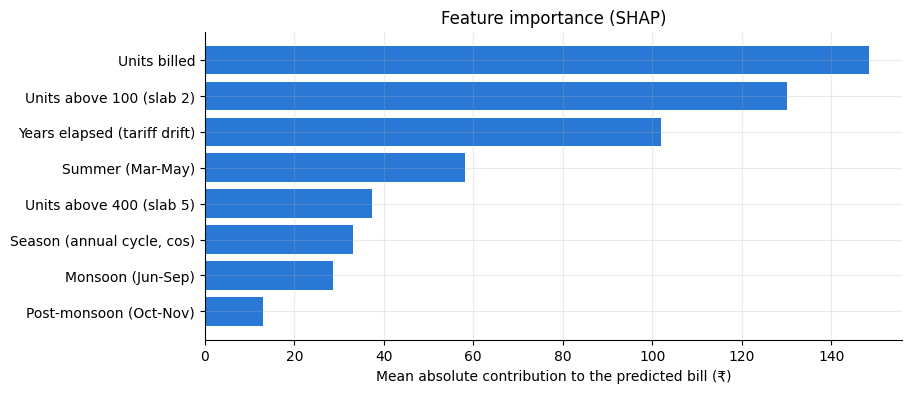

SHAP attributes most of this model's output to Units billed, Units above 100 (slab 2) and Years elapsed (tariff drift).


In [15]:
from src.explain import compute_shap, narrate
from src.features import build_tariff_frame

X = build_tariff_frame(modelling_frame(result.bills), result.tariff_model.origin)
expl = compute_shap(result.tariff_model.fitted, X)
top = expl.importance.head(8).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top["feature"], top["mean_abs_shap"], color=BLUE)
ax.set(xlabel="Mean absolute contribution to the predicted bill (₹)",
       title=f"Feature importance ({expl.method})")
plt.show()

print(narrate(expl))

Units billed, units above the 100-unit slab, and years elapsed — exactly the
shape of a block tariff with annual revisions. That is a useful sanity check
that the model learned the tariff rather than a coincidence in the data.

---

## Takeaways

1. **The counterfactual is the whole problem.** Two independent estimates that
   agree to 77% are worth far more than one confident number.
2. **Model choice is a constraint problem, not just a metric problem.** Trees
   won on CV MAE and were still the wrong choice for the extrapolation task.
3. **Cleaning decisions moved the answer more than model choice did.** A
   seasonal fill that invented solar output, and one arrears bill, each shifted
   the result more than swapping RandomForest for ExtraTrees.
4. **Report the uncomfortable result.** The array pays back in cash and loses
   to a fixed deposit. Both belong in the output.